In [18]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [19]:
feature_names = [
    "id", "diagnosis", "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean", "concave points_mean",
    "symmetry_mean", "fractal_dimension_mean", "radius_se", "texture_se", "perimeter_se",
    "area_se", "smoothness_se", "compactness_se", "concavity_se", "concave points_se",
    "symmetry_se", "fractal_dimension_se", "radius_worst", "texture_worst",
    "perimeter_worst", "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave points_worst", "symmetry_worst", "fractal_dimension_worst"
]

df = pd.read_csv("data.csv", header=None, names=feature_names)

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (569, 32)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  

In [20]:
df = df.drop(columns=['id'])
df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [21]:
x = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print("Features:", x.shape)
print("Target:", y.shape)

Features: (569, 30)
Target: (569,)


In [22]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [23]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [24]:
pca = PCA(n_components=2)

In [25]:
x_train_pca = pca.fit_transform(x_train_scaled)
x_test_pca = pca.transform(x_test_scaled)

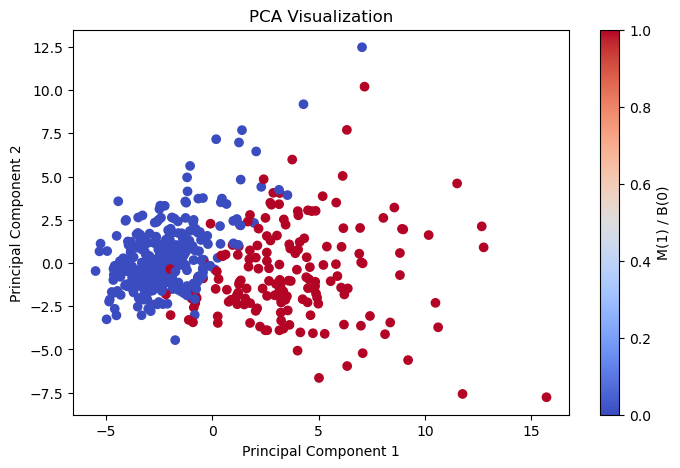

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(x_train_pca[:, 0], x_train_pca[:, 1], c=(y_train == "M"), cmap="coolwarm")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")
plt.colorbar(label="M(1) / B(0)")
plt.show()

In [27]:
model1 = LogisticRegression(max_iter=1000, random_state=42)
model1.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
y_pred1 = model1.predict(x_test_scaled)

In [29]:
acc1 = accuracy_score(y_test, y_pred1)
print("Accuracy before PCA:",acc1)
prec1 =  precision_score(y_test, y_pred1, pos_label="M")
print("Precison before PCA",prec1)
recall1 =  recall_score(y_test, y_pred1, pos_label="M")
print("Recall before PCA",recall1)
f11 =  f1_score(y_test, y_pred1, pos_label="M")
print("F1 before PCA",f11)

Accuracy before PCA: 0.9649122807017544
Precison before PCA 0.975
Recall before PCA 0.9285714285714286
F1 before PCA 0.9512195121951219


In [30]:
model2 = LogisticRegression(max_iter=1000, random_state=42)
model2.fit(x_train_pca, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [31]:
y_pred2 = model2.predict(x_test_pca)

In [32]:
acc2 = accuracy_score(y_test, y_pred2)
print("Accuracy after PCA:", acc2)
prec2 = precision_score(y_test, y_pred2, pos_label="M")
print("Precision after PCA:", prec2)
recall2 = recall_score(y_test, y_pred2, pos_label="M")
print("Recall after PCA:", recall2)
f12 = f1_score(y_test, y_pred2, pos_label="M")
print("F1 after PCA:", f12)

Accuracy after PCA: 0.9473684210526315
Precision after PCA: 0.9736842105263158
Recall after PCA: 0.8809523809523809
F1 after PCA: 0.925


In [33]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Before PCA": [acc1, prec1, recall1, f11],
    "After PCA": [acc2, prec2, recall2, f12]
})

print(comparison.round(4))

      Metric  Before PCA  After PCA
0   Accuracy      0.9649     0.9474
1  Precision      0.9750     0.9737
2     Recall      0.9286     0.8810
3   F1-Score      0.9512     0.9250


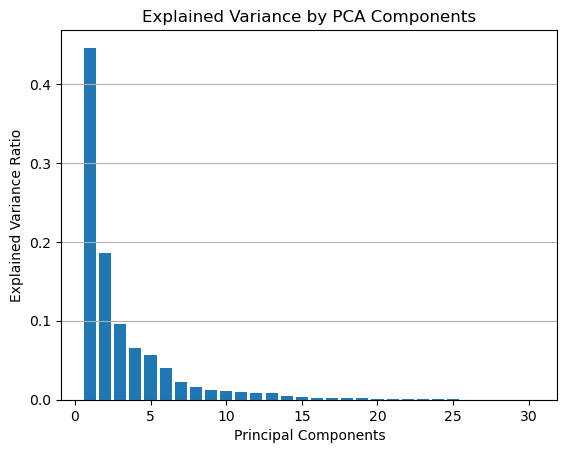

In [35]:
pca_all = PCA().fit(x_train_scaled)

plt.bar(range(1, 31), pca_all.explained_variance_ratio_)
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by PCA Components")
plt.grid(axis='y')
plt.show()